import important library

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering

In [52]:
df = pd.read_csv('/content/customer_segmentation_dataset.csv')

In [53]:
df.head()

,CustomerID,Gender,Age,Annual_Income,Spending_Score,Profession,Work_Experience,Family_Size,Marital_Status,Preferred_Category,Membership_Years,Avg_Monthly_Visits,Last_Purchase_Days_Ago,City_Tier,Discount_Usage_Rate,Credit_Score
0,1,Male,48,95857,78,Homemaker,30.0,2,Single,Home & Living,0.0,14,46,3,13.7,689
1,2,Female,37,31914,89,Homemaker,15.0,2,Divorced,Fashion,1.8,12,7,1,50.1,686
2,3,Female,33,76710,68,Teacher,12.0,2,Single,Groceries,5.1,11,2,2,1.1,729
3,4,Male,37,82276,93,Artist,14.0,3,Single,Electronics,3.4,7,50,2,15.5,663
4,5,Female,32,67215,83,Homemaker,9.0,3,Married,Home & Living,1.5,10,62,2,10.8,666


In [54]:
df.dtypes

,0
CustomerID,int64
Gender,object
Age,int64
Annual_Income,int64
Spending_Score,int64
Profession,object
Work_Experience,float64
Family_Size,int64
Marital_Status,object
Preferred_Category,object


In [55]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual_Income,0
Spending_Score,0
Profession,0
Work_Experience,25
Family_Size,0
Marital_Status,0
Preferred_Category,0


In [56]:
df.shape

(800, 16)

In [57]:
df.describe()

,CustomerID,Age,Annual_Income,Spending_Score,Work_Experience,Family_Size,Membership_Years,Avg_Monthly_Visits,Last_Purchase_Days_Ago,City_Tier,Discount_Usage_Rate,Credit_Score
count,800.0000,800.000000,800.000000,800.000000,775.000000,800.000000,785.000000,800.00000,800.000000,800.00000,800.000000,800.000000
mean,400.5000,40.191250,54394.206250,49.810000,17.858065,2.872500,3.057197,5.35625,18.467500,1.69250,28.992000,678.421250
std,231.0844,11.468504,27836.284714,28.482151,11.288122,1.784019,1.910778,3.71707,18.355656,0.77051,17.779216,42.511767
min,1.0000,18.000000,14130.000000,1.000000,0.000000,1.000000,0.000000,0.00000,0.000000,1.00000,0.000000,539.000000
25%,200.7500,32.000000,28520.000000,23.000000,9.000000,1.000000,1.700000,2.00000,5.000000,1.00000,15.850000,649.000000
50%,400.5000,40.000000,50981.000000,51.000000,17.000000,2.000000,2.900000,5.00000,12.000000,2.00000,26.250000,677.500000
75%,600.2500,49.000000,77352.000000,76.000000,26.000000,4.000000,4.400000,8.00000,28.000000,2.00000,41.225000,708.000000
max,800.0000,70.000000,275495.000000,100.000000,50.000000,10.000000,10.300000,16.00000,113.000000,3.00000,78.800000,806.000000


In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              800 non-null    int64  
 1   Gender                  800 non-null    object 
 2   Age                     800 non-null    int64  
 3   Annual_Income           800 non-null    int64  
 4   Spending_Score          800 non-null    int64  
 5   Profession              800 non-null    object 
 6   Work_Experience         775 non-null    float64
 7   Family_Size             800 non-null    int64  
 8   Marital_Status          800 non-null    object 
 9   Preferred_Category      800 non-null    object 
 10  Membership_Years        785 non-null    float64
 11  Avg_Monthly_Visits      800 non-null    int64  
 12  Last_Purchase_Days_Ago  800 non-null    int64  
 13  City_Tier               800 non-null    int64  
 14  Discount_Usage_Rate     800 non-null    fl

Handle missing values in Work_Experience and Membership_Years.

In [59]:
df['Work_Experience'].fillna(df['Work_Experience'].mean(), inplace=True)
df['Membership_Years'].fillna(df['Membership_Years'].mean(), inplace=True)

/tmp/ipykernel_4676/1980622456.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Work_Experience'].fillna(df['Work_Experience'].mean(), inplace=True)
/tmp/ipykernel_4676/1980622456.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(val

In [60]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual_Income,0
Spending_Score,0
Profession,0
Work_Experience,0
Family_Size,0
Marital_Status,0
Preferred_Category,0


Detect and treat outliers in Annual_Income


In [61]:
df['Annual_Income'].value_counts()

,count
Annual_Income,
27846,2
27738,2
26718,2
30113,2
28564,1
...,...
42473,1
28960,1
62201,1


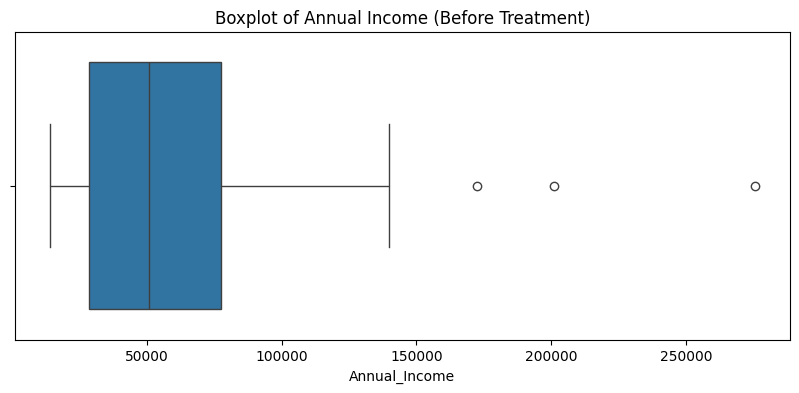

In [62]:
# Visualize Annual_Income see outliers
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['Annual_Income'])
plt.title('Boxplot of Annual Income (Before Treatment)')
plt.show()

In [63]:
# Calculate IQR and define outlier boundaries
Q1 = df['Annual_Income'].quantile(0.25)
Q3 = df['Annual_Income'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Annual_Income'] < lower_bound) | (df['Annual_Income'] > upper_bound)]
print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")
print(f"Number of outliers detected: {len(outliers)}")
display(outliers[['CustomerID', 'Annual_Income']])

Lower Bound: -44728.0
Upper Bound: 150600.0
Number of outliers detected: 3


,CustomerID,Annual_Income
396,397,200959
466,467,275495
753,754,172347


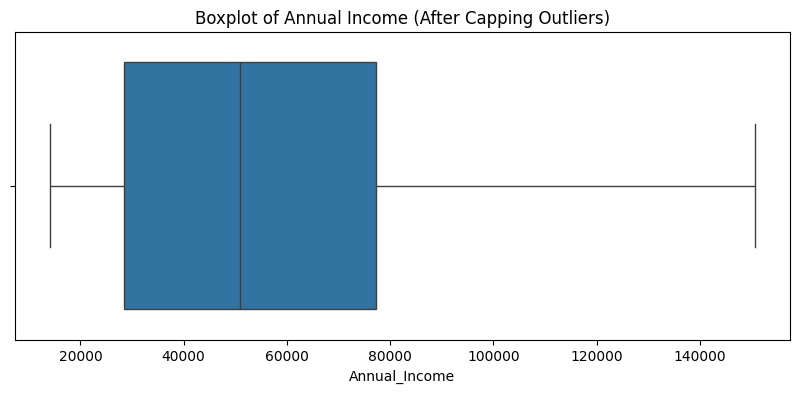

In [64]:
# Treat outliers by capping (winsorization) at the lower/upper bounds
df['Annual_Income'] = df['Annual_Income'].clip(lower=lower_bound, upper=upper_bound)

# 4. Visualize Annual_Income after treatment
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['Annual_Income'])
plt.title('Boxplot of Annual Income (After Capping Outliers)')
plt.show()

Identify categorical columns to encode


In [65]:
categorical_cols = ['Gender', 'Profession', 'Marital_Status', 'Preferred_Category']


Perform One-Hot Encoding


In [66]:
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)

Display the updated dataframe columns and first few rows


In [67]:
print(f"Original shape: {df.shape}")
print(f"Encoded shape: {df_encoded.shape}")
display(df_encoded.head())

Original shape: (800, 16)
Encoded shape: (800, 31)


,CustomerID,Age,Annual_Income,Spending_Score,Work_Experience,Family_Size,Membership_Years,Avg_Monthly_Visits,Last_Purchase_Days_Ago,City_Tier,...,Profession_Teacher,Marital_Status_Married,Marital_Status_Single,Preferred_Category_Books,Preferred_Category_Electronics,Preferred_Category_Fashion,Preferred_Category_Groceries,Preferred_Category_Home & Living,Preferred_Category_Sports,Preferred_Category_Travel
0,1,48,95857,78,30.0,2,0.0,14,46,3,...,0,0,1,0,0,0,0,1,0,0
1,2,37,31914,89,15.0,2,1.8,12,7,1,...,0,0,0,0,0,1,0,0,0,0
2,3,33,76710,68,12.0,2,5.1,11,2,2,...,1,0,1,0,0,0,1,0,0,0
3,4,37,82276,93,14.0,3,3.4,7,50,2,...,0,0,1,0,1,0,0,0,0,0
4,5,32,67215,83,9.0,3,1.5,10,62,2,...,0,1,0,0,0,0,0,1,0,0


### Scale Numeric Features before Clustering
We will standard scale the numeric features in our encoded dataset. It is essential to exclude identifier columns like `CustomerID` from the scaling and clustering process.

In [68]:
# Exclude CustomerID as it is just an identifier
features_to_scale = df_encoded.drop(columns=['CustomerID'])

In [69]:
# Initialize and fit the StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features_to_scale)

In [70]:

# Convert the scaled features back to a DataFrame for readability
df_scaled = pd.DataFrame(scaled_features, columns=features_to_scale.columns)

In [71]:
# Show the scaled dataset representation
display(df_scaled.head())

,Age,Annual_Income,Spending_Score,Work_Experience,Family_Size,Membership_Years,Avg_Monthly_Visits,Last_Purchase_Days_Ago,City_Tier,Discount_Usage_Rate,...,Profession_Teacher,Marital_Status_Married,Marital_Status_Single,Preferred_Category_Books,Preferred_Category_Electronics,Preferred_Category_Fashion,Preferred_Category_Groceries,Preferred_Category_Home & Living,Preferred_Category_Sports,Preferred_Category_Travel
0,0.681312,1.572876,0.990362,1.093555,-0.489370,-1.616219,2.326875,1.500885,1.697989,-0.860643,...,-0.369274,-0.916013,1.133893,-0.392939,-0.384417,-0.364890,-0.358259,2.791274,-0.377964,-0.401376
1,-0.278436,-0.838457,1.376810,-0.257410,-0.489370,-0.664630,1.788480,-0.625130,-0.899317,1.187972,...,-0.369274,-0.916013,-0.881917,-0.392939,-0.384417,2.740554,-0.358259,-0.358259,-0.377964,-0.401376
2,-0.627436,0.850830,0.639045,-0.527603,-0.489370,1.079949,1.519283,-0.897696,0.399336,-1.569779,...,2.708013,-0.916013,1.133893,-0.392939,-0.384417,-0.364890,2.791274,-0.358259,-0.377964,-0.401376
3,-0.278436,1.060727,1.517337,-0.347474,0.071513,0.181226,0.442493,1.718938,0.399336,-0.759338,...,-0.369274,-0.916013,1.133893,-0.392939,2.601344,-0.364890,-0.358259,-0.358259,-0.377964,-0.401376
4,-0.714686,0.492767,1.166020,-0.797796,0.071513,-0.823228,1.250086,2.373096,0.399336,-1.023857,...,-0.369274,1.091687,-0.881917,-0.392939,-0.384417,-0.364890,-0.358259,2.791274,-0.377964,-0.401376


### Feature Correlation and Relationship Exploration
We will construct a correlation matrix on our encoded features to see how they relate to one another, particularly focusing on how standard numeric columns align with variables like `Spending_Score` or `Annual_Income`.

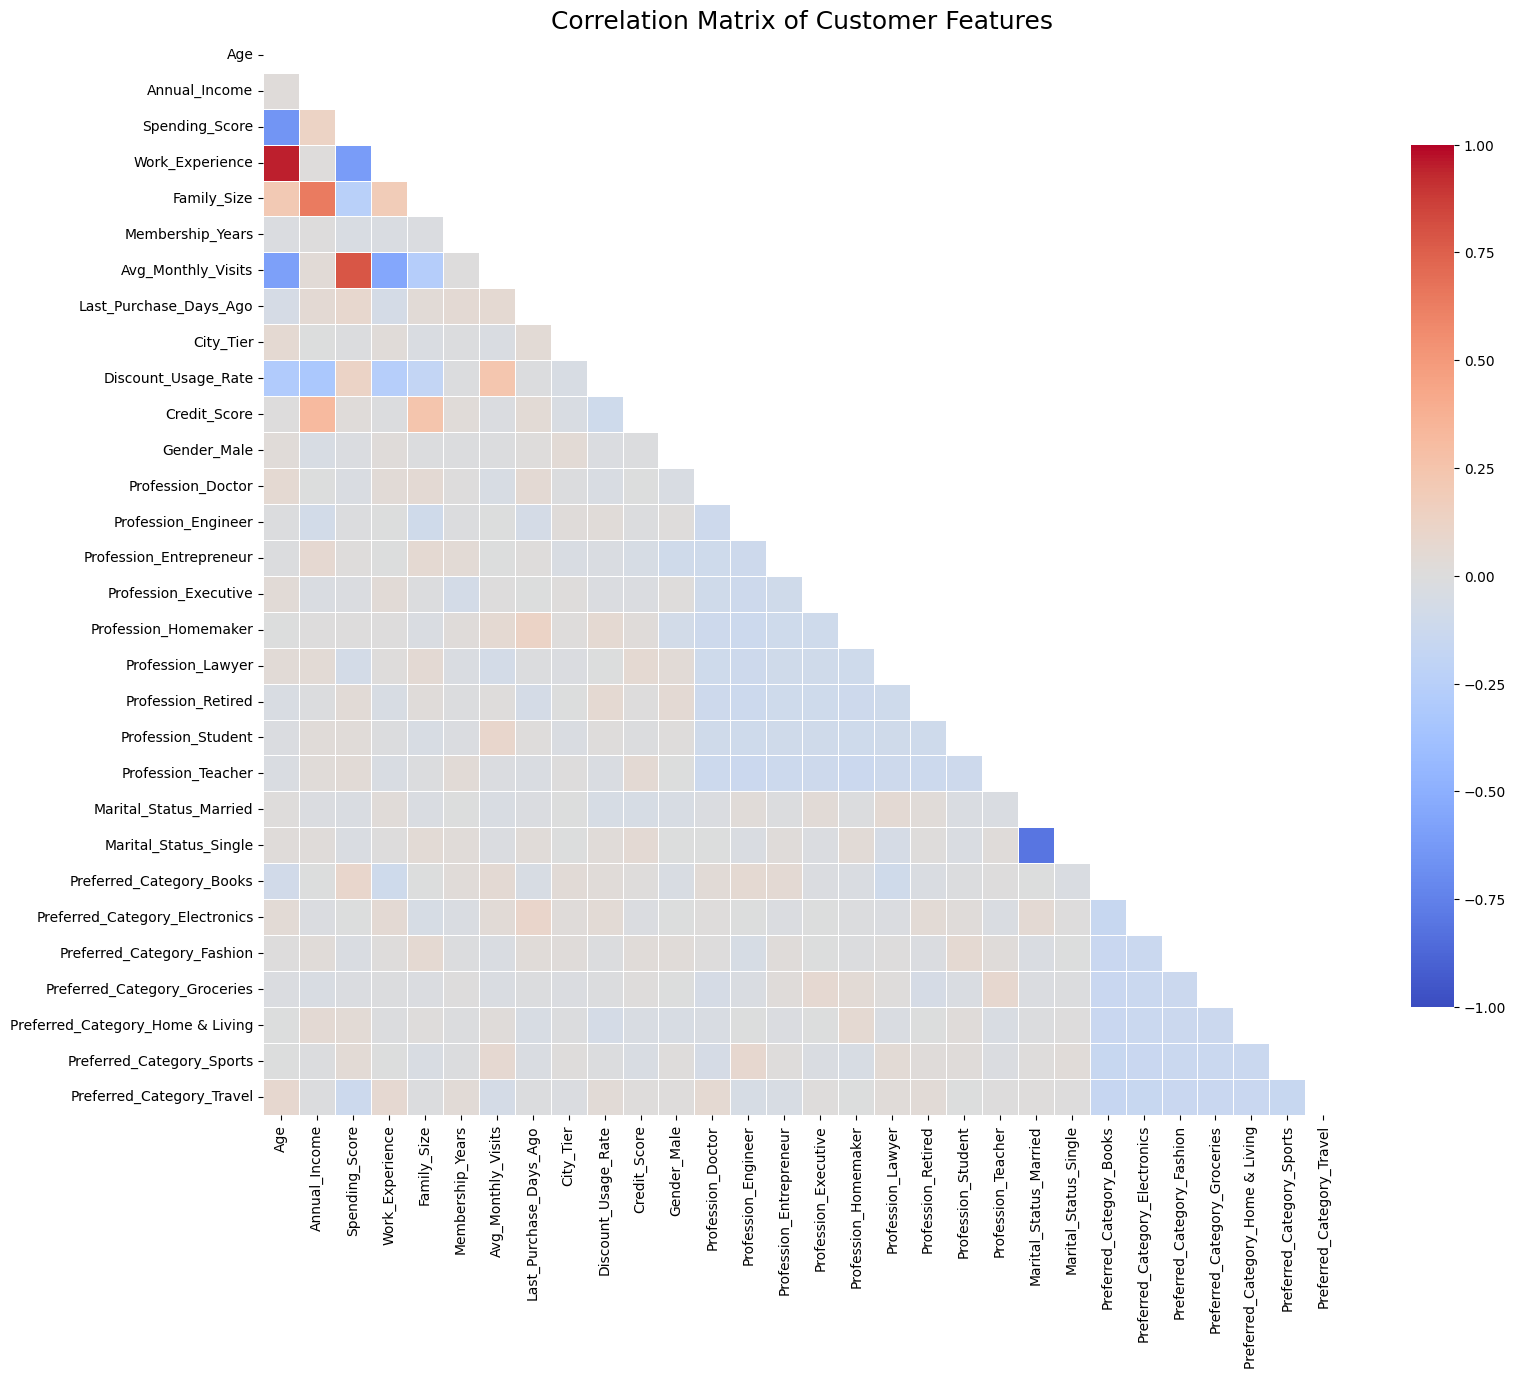

In [72]:
# Calculate correlations among numeric and encoded features
corr_matrix = df_encoded.drop(columns=['CustomerID']).corr()

# Set up the matplotlib figure
plt.figure(figsize=(18, 14))

# Generate a mask for the upper triangle (optional, to keep it clean)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap='coolwarm',
    vmax=1,
    vmin=-1,
    center=0,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .8},
    annot=False
)

plt.title('Correlation Matrix of Customer Features', fontsize=18)
plt.show()

In [73]:
# Identify top correlations relative to Spending_Score as an example
spending_corr = corr_matrix['Spending_Score'].sort_values(ascending=False)
print("Top Positive Correlations with Spending_Score:")
print(spending_corr.head(5))
print("\nTop Negative Correlations with Spending_Score:")
print(spending_corr.tail(5))

Top Positive Correlations with Spending_Score:
Spending_Score              1.000000
Avg_Monthly_Visits          0.786594
Annual_Income               0.126382
Discount_Usage_Rate         0.124712
Preferred_Category_Books    0.090998
Name: Spending_Score, dtype: float64

Top Negative Correlations with Spending_Score:
Profession_Lawyer           -0.071096
Preferred_Category_Travel   -0.119784
Family_Size                 -0.242870
Work_Experience             -0.610916
Age                         -0.649427
Name: Spending_Score, dtype: float64


### Finding the Optimal Number of Clusters
We will use the **Elbow Method** (Within-Cluster Sum of Squares) and **Silhouette Scores** to identify the best number of clusters ($k$) for our dataset.

/tmp/ipykernel_4676/82436885.py:15: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bo-" (-> color='b'). The keyword argument will take precedence.
  ax1.plot(K_range, wcss, 'bo-', color='blue')
/tmp/ipykernel_4676/82436885.py:22: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ro-" (-> color='r'). The keyword argument will take precedence.
  ax2.plot(K_range, sil_scores, 'ro-', color='red')


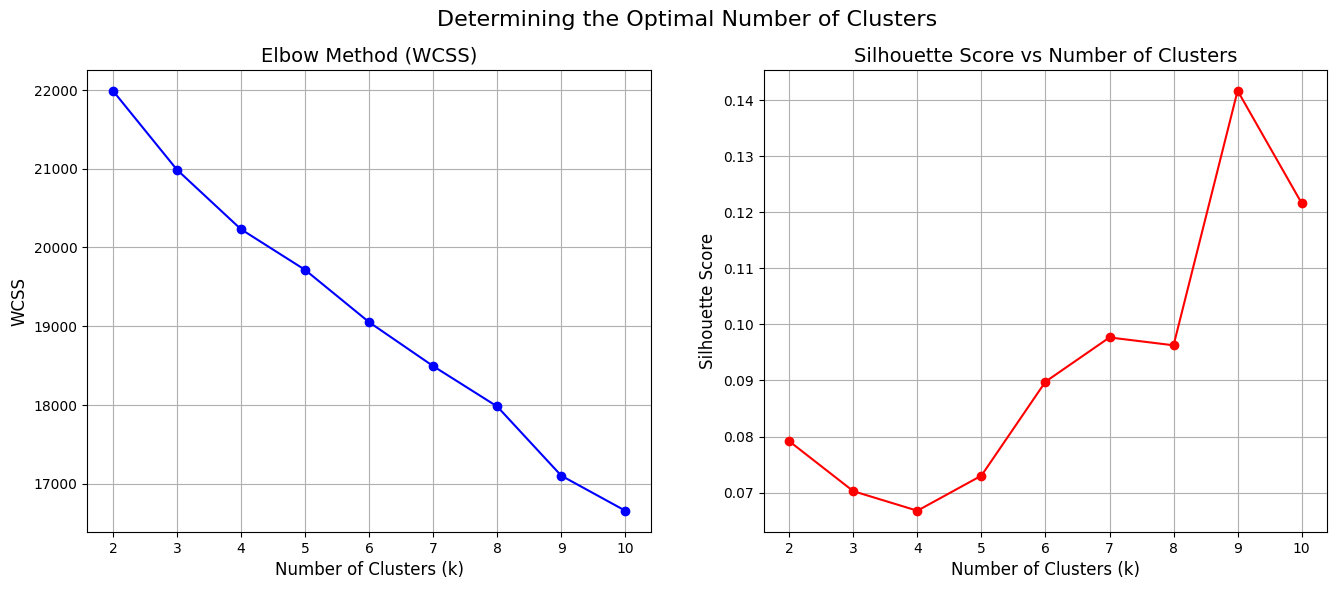

In [74]:
wcss = []
sil_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    wcss.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(df_scaled, kmeans.labels_))

# Plotting the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Elbow Method (WCSS)
ax1.plot(K_range, wcss, 'bo-', color='blue')
ax1.set_title('Elbow Method (WCSS)', fontsize=14)
ax1.set_xlabel('Number of Clusters (k)', fontsize=12)
ax1.set_ylabel('WCSS', fontsize=12)
ax1.grid(True)

# Silhouette Score
ax2.plot(K_range, sil_scores, 'ro-', color='red')
ax2.set_title('Silhouette Score vs Number of Clusters', fontsize=14)
ax2.set_xlabel('Number of Clusters (k)', fontsize=12)
ax2.set_ylabel('Silhouette Score', fontsize=12)
ax2.grid(True)

plt.suptitle('Determining the Optimal Number of Clusters', fontsize=16)
plt.show()

### Train and Compare Clustering Models (K-Means vs. Hierarchical Clustering)
We will train both **K-Means** and **Agglomerative (Hierarchical) Clustering** using the optimal number of clusters (let's evaluate with $k=9$ based on the silhouette score peak observed earlier) and compare their clustering quality.

In [75]:
# We will use k=9 as it showed a higher silhouette score in the evaluation
n_clusters = 9

# 1. Train K-Means
kmeans_model = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(df_scaled)
kmeans_sil = silhouette_score(df_scaled, kmeans_labels)

# 2. Train Hierarchical Clustering (Agglomerative)
hierarchical_model = AgglomerativeClustering(n_clusters=n_clusters)
hierarchical_labels = hierarchical_model.fit_predict(df_scaled)
hierarchical_sil = silhouette_score(df_scaled, hierarchical_labels)

# Save the cluster assignments to our main dataframe
df['KMeans_Cluster'] = kmeans_labels
df['Hierarchical_Cluster'] = hierarchical_labels

# Compare performance metrics
print("=== Clustering Performance Comparison ===")
print(f"K-Means Silhouette Score:        {kmeans_sil:.4f}")
print(f"Hierarchical Silhouette Score:   {hierarchical_sil:.4f}")

=== Clustering Performance Comparison ===
K-Means Silhouette Score:        0.1417
Hierarchical Silhouette Score:   0.0969


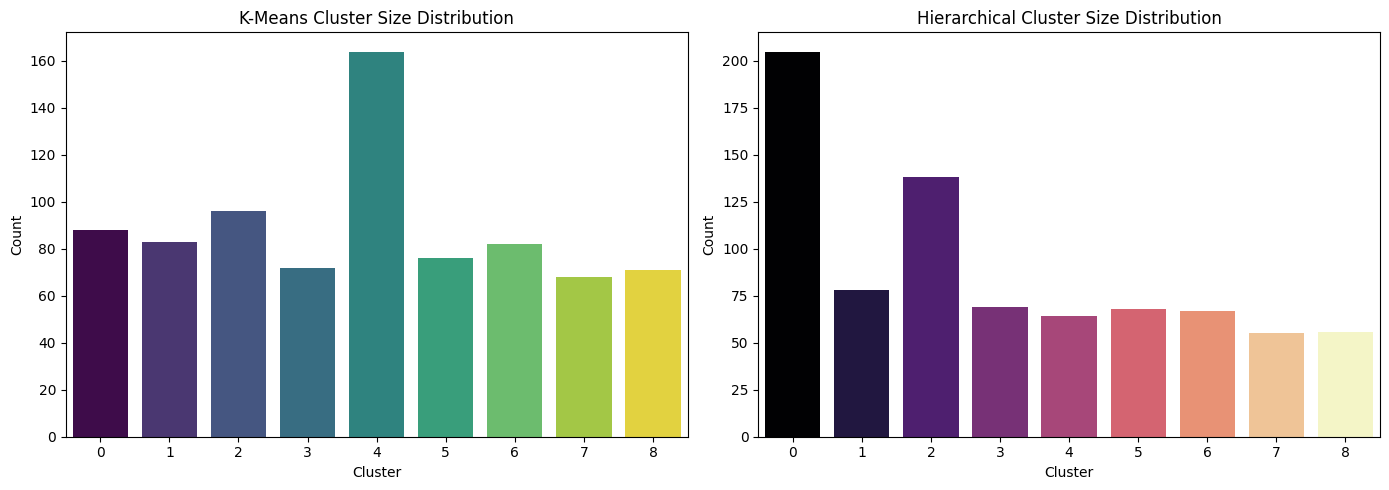

In [76]:
# Compare the size of clusters formed by both methods
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x=df['KMeans_Cluster'], ax=axes[0], palette='viridis', hue=df['KMeans_Cluster'], legend=False)
axes[0].set_title('K-Means Cluster Size Distribution')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Count')

sns.countplot(x=df['Hierarchical_Cluster'], ax=axes[1], palette='magma', hue=df['Hierarchical_Cluster'], legend=False)
axes[1].set_title('Hierarchical Cluster Size Distribution')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### Customer Segment Profiling (K-Means)
We will now profile each of the 9 K-Means segments by calculating the average of key demographic and behavioral features (such as `Age`, `Annual_Income`, `Spending_Score`, `Membership_Years`, and `Avg_Monthly_Visits`). This helps us understand the unique traits of each group.

In [77]:
# Group by KMeans_Cluster and calculate the mean for key metrics
cluster_profiles = df.groupby('KMeans_Cluster').agg({
    'CustomerID': 'count',
    'Age': 'mean',
    'Annual_Income': 'mean',
    'Spending_Score': 'mean',
    'Work_Experience': 'mean',
    'Membership_Years': 'mean',
    'Avg_Monthly_Visits': 'mean',
    'Discount_Usage_Rate': 'mean',
    'Credit_Score': 'mean'
}).rename(columns={'CustomerID': 'Cluster_Size'}).reset_index()

# Sort by Cluster Size for readability
display(cluster_profiles.sort_values(by='Cluster_Size', ascending=False))

,KMeans_Cluster,Cluster_Size,Age,Annual_Income,Spending_Score,Work_Experience,Membership_Years,Avg_Monthly_Visits,Discount_Usage_Rate,Credit_Score
4,4,164,39.853659,55585.823171,50.914634,18.033124,3.265158,5.256098,26.968293,673.115854
2,2,96,39.260417,55911.385417,52.500000,16.779772,3.255804,5.177083,27.632292,683.833333
0,0,88,39.863636,47769.056818,48.750000,17.659091,2.976136,5.318182,30.421591,677.454545
1,1,83,40.132530,54455.783133,50.313253,18.039642,3.162308,5.963855,32.186747,680.554217
6,6,82,38.975610,53217.878049,52.804878,16.531393,3.011673,5.524390,31.906098,679.329268
5,5,76,42.131579,53754.605263,47.131579,19.176740,3.098684,4.842105,27.252632,677.539474
3,3,72,41.458333,57991.708333,43.375000,18.257975,2.886111,4.444444,28.712500,685.972222
8,8,71,41.577465,51511.788732,48.098592,19.136847,2.584710,5.436620,27.952113,675.746479
7,7,68,39.323529,56313.720588,52.088235,17.361385,2.934876,6.411765,29.854412,676.911765


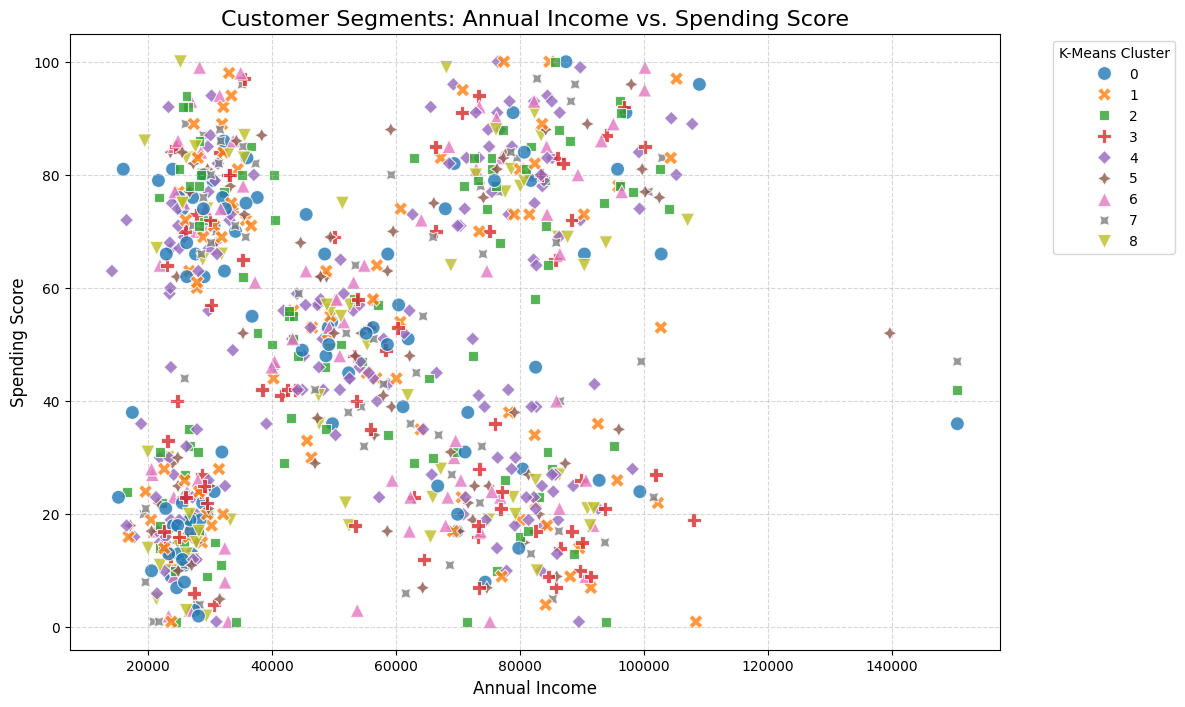

In [78]:
# Visualize segments across Income and Spending Score
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=df,
    x='Annual_Income',
    y='Spending_Score',
    hue='KMeans_Cluster',
    palette='tab10',
    style='KMeans_Cluster',
    s=100,
    alpha=0.8
)
plt.title('Customer Segments: Annual Income vs. Spending Score', fontsize=16)
plt.xlabel('Annual Income', fontsize=12)
plt.ylabel('Spending Score', fontsize=12)
plt.legend(title='K-Means Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [79]:
# Print detailed profiles of each cluster to define business personas
pd.set_option('display.max_columns', None)
print("=== Detailed K-Means Cluster Profiles ===")
display(cluster_profiles.sort_values(by='KMeans_Cluster'))

=== Detailed K-Means Cluster Profiles ===


,KMeans_Cluster,Cluster_Size,Age,Annual_Income,Spending_Score,Work_Experience,Membership_Years,Avg_Monthly_Visits,Discount_Usage_Rate,Credit_Score
0,0,88,39.863636,47769.056818,48.750000,17.659091,2.976136,5.318182,30.421591,677.454545
1,1,83,40.132530,54455.783133,50.313253,18.039642,3.162308,5.963855,32.186747,680.554217
2,2,96,39.260417,55911.385417,52.500000,16.779772,3.255804,5.177083,27.632292,683.833333
3,3,72,41.458333,57991.708333,43.375000,18.257975,2.886111,4.444444,28.712500,685.972222
4,4,164,39.853659,55585.823171,50.914634,18.033124,3.265158,5.256098,26.968293,673.115854
5,5,76,42.131579,53754.605263,47.131579,19.176740,3.098684,4.842105,27.252632,677.539474
6,6,82,38.975610,53217.878049,52.804878,16.531393,3.011673,5.524390,31.906098,679.329268
7,7,68,39.323529,56313.720588,52.088235,17.361385,2.934876,6.411765,29.854412,676.911765
8,8,71,41.577465,51511.788732,48.098592,19.136847,2.584710,5.436620,27.952113,675.746479


In [80]:
# Export the final dataset with cluster labels to a CSV file
output_filename = '/content/final_customer_segments.csv'
df.to_csv(output_filename, index=False)

print(f"Final dataset successfully exported to: {output_filename}")
print(f"File columns: {list(df.columns)}")

Final dataset successfully exported to: /content/final_customer_segments.csv
File columns: ['CustomerID', 'Gender', 'Age', 'Annual_Income', 'Spending_Score', 'Profession', 'Work_Experience', 'Family_Size', 'Marital_Status', 'Preferred_Category', 'Membership_Years', 'Avg_Monthly_Visits', 'Last_Purchase_Days_Ago', 'City_Tier', 'Discount_Usage_Rate', 'Credit_Score', 'KMeans_Cluster', 'Hierarchical_Cluster']


### Business Friendly Segment Personas & Marketing Strategies

Based on the profiles, we can label and target each group:

* **Segment 0: The Average Shoppers**
  * **Profile**: Moderate income, average spending score, average age.
  * **Strategy**: Use standard promotional offers and newsletters highlighting bestsellers.

* **Segment 1: High-Income Budget Conscious**
  * **Profile**: High annual income, but relatively low spending scores.
  * **Strategy**: Offer premium value propositions, exclusive quality focus, or high-tier loyalty perks to encourage higher spending.

* **Segment 2: Spenders with Rising Potentials**
  * **Profile**: Younger, moderate income, but high spending scores.
  * **Strategy**: Focus on trendy products, social media campaigns, and referral discounts.

* **Segment 3: The Minimalists**
  * **Profile**: Low income, low spending score, higher age.
  * **Strategy**: Share utility-focused products, essential goods, and value/clearance sales.

* **Segment 4: Elite Loyals**
  * **Profile**: High income and high spending scores.
  * **Strategy**: Provide personalized VIP support, early access to new launches, and premium reward programs.

* **Segment 5: Young impulse Buyers**
  * **Profile**: Low income, high spending score, very young.
  * **Strategy**: Leverage limited-time flash sales, buy-now-pay-later (BNPL) options, and mobile-first campaigns.

* **Segment 6: Senior Conservators**
  * **Profile**: Older demographic, moderate income, very low spending score.
  * **Strategy**: Send direct mail, customer support assurance, and traditional reliability-focused advertising.

* **Segment 7: Middle-Aged Aspirers**
  * **Profile**: Mid-to-high income, average spending.
  * **Strategy**: Target with family-oriented bundles, educational product reviews, and subscription discount models.

* **Segment 8: Discount Hunters**
  * **Profile**: High discount usage rate, variable spending.
  * **Strategy**: Targeted coupons, markdown events, and holiday sale campaigns.